In [1]:
from pca_utils import *

# Import data

In [9]:
path1 = "/mnt/c/users/helen/Desktop/190226/WT/foci2/aggregated_data.csv"
path2 = "/mnt/c/users/helen/Desktop/190226/MGS1/foci2/aggregated_data.csv"
path3 = "/mnt/c/users/helen/Desktop/190226/MGS2/foci2/aggregated_data.csv"
path4 = "/mnt/c/users/helen/Desktop/190226/MGS3/foci2/aggregated_data.csv"
path5 = "/mnt/c/users/helen/Desktop/190226/MGS4/foci2/aggregated_data.csv"
path6 = "/mnt/c/users/helen/Desktop/190226/MGS5/foci2/aggregated_data.csv"

In [10]:
df1 = pd.read_csv(path1)
df2 = pd.read_csv(path2)
df3 = pd.read_csv(path3)
df4 = pd.read_csv(path4)
df5 = pd.read_csv(path5)
df6 = pd.read_csv(path6)

In [11]:
df1["sample"] = "WT"
df2["sample"] = "MGS1"
df3["sample"] = "MGS2"
df4["sample"] = "MGS3"
df5["sample"] = "MGS4"
df6["sample"] = "MGS5"

combined_df = pd.concat(
    [df1, df2, df3, df4, df5, df6],
    ignore_index=True
)

In [12]:
# Clean data
combined_df.columns = combined_df.columns.str.strip().str.lower()
combined_df.iloc[:, 1:10] = combined_df.iloc[:, 1:10].apply(pd.to_numeric, errors="coerce")
df = combined_df.dropna()

print("Number of cells is:", df.shape[0])

Number of cells is: 204


In [13]:
combined_df

,image_id,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity,sample
0,C2_MP_U2OS_fixed_WT_001.nd2_(series_05)_ROI_02...,452,3.0,1.954410,0.938083,1.000000,3.207107,15.500000,18.0,13.0,WT
1,C2_MP_U2OS_fixed_WT_001.nd2_(series_06)_ROI_02...,373,3.0,1.954410,0.960141,1.000000,3.207107,25.500000,28.0,23.0,WT
2,C2_MP_U2OS_fixed_WT_001.nd2_(series_08)_ROI_02...,360,2.0,1.595769,1.000000,1.000000,0.000000,29.000000,32.0,25.0,WT
3,C2_MP_U2OS_fixed_WT_001.nd2_(series_10)_ROI_02...,268,3.0,1.954410,1.000000,1.000000,1.000000,25.309525,28.0,22.0,WT
4,C2_MP_U2OS_fixed_WT_001.nd2_(series_11)_ROI_02...,49,6.0,2.763953,0.836390,0.868421,6.414214,30.000000,35.0,25.0,WT
...,...,...,...,...,...,...,...,...,...,...,...
199,C2_MP_U2OS_fixed_MGS5_002.nd2_(series_16)_ROI_...,232,3.0,1.954410,0.938083,1.000000,3.414214,42.500000,47.0,38.0,MGS5
200,C2_MP_U2OS_fixed_MGS5_002.nd2_(series_17)_ROI_...,335,3.0,1.954410,0.938968,1.000000,3.414214,22.200001,25.0,19.0,MGS5
201,C2_MP_U2OS_fixed_MGS5_002.nd2_(series_19)_ROI_...,215,3.0,1.954410,1.000000,1.000000,1.000000,35.500000,39.0,32.0,MGS5
202,C2_MP_U2OS_fixed_MGS5_002.nd2_(series_20)_ROI_...,143,3.0,1.954410,0.924176,1.000000,3.207107,45.500000,50.0,41.0,MGS5


# Correlation analysis

In [14]:
# Select numerical columns
df_numeric = df.select_dtypes(include=np.number)

# Calculate Spearman correlation
corr = df_numeric.corr(method="spearman")

display(corr.round(3))

,n_foci,area,equivalent_diameter_area,eccentricity,solidity,perimeter,mean_intensity,max_intensity,min_intensity
n_foci,1.000,-0.636,-0.636,0.660,0.651,-0.600,-0.669,-0.675,-0.657
area,-0.636,1.000,1.000,-0.806,-0.798,0.841,0.684,0.694,0.655
equivalent_diameter_area,-0.636,1.000,1.000,-0.806,-0.798,0.841,0.684,0.694,0.655
eccentricity,0.660,-0.806,-0.806,1.000,0.684,-0.961,-0.694,-0.702,-0.664
solidity,0.651,-0.798,-0.798,0.684,1.000,-0.697,-0.615,-0.625,-0.596
perimeter,-0.600,0.841,0.841,-0.961,-0.697,1.000,0.693,0.701,0.661
mean_intensity,-0.669,0.684,0.684,-0.694,-0.615,0.693,1.000,0.998,0.996
max_intensity,-0.675,0.694,0.694,-0.702,-0.625,0.701,0.998,1.000,0.994
min_intensity,-0.657,0.655,0.655,-0.664,-0.596,0.661,0.996,0.994,1.000


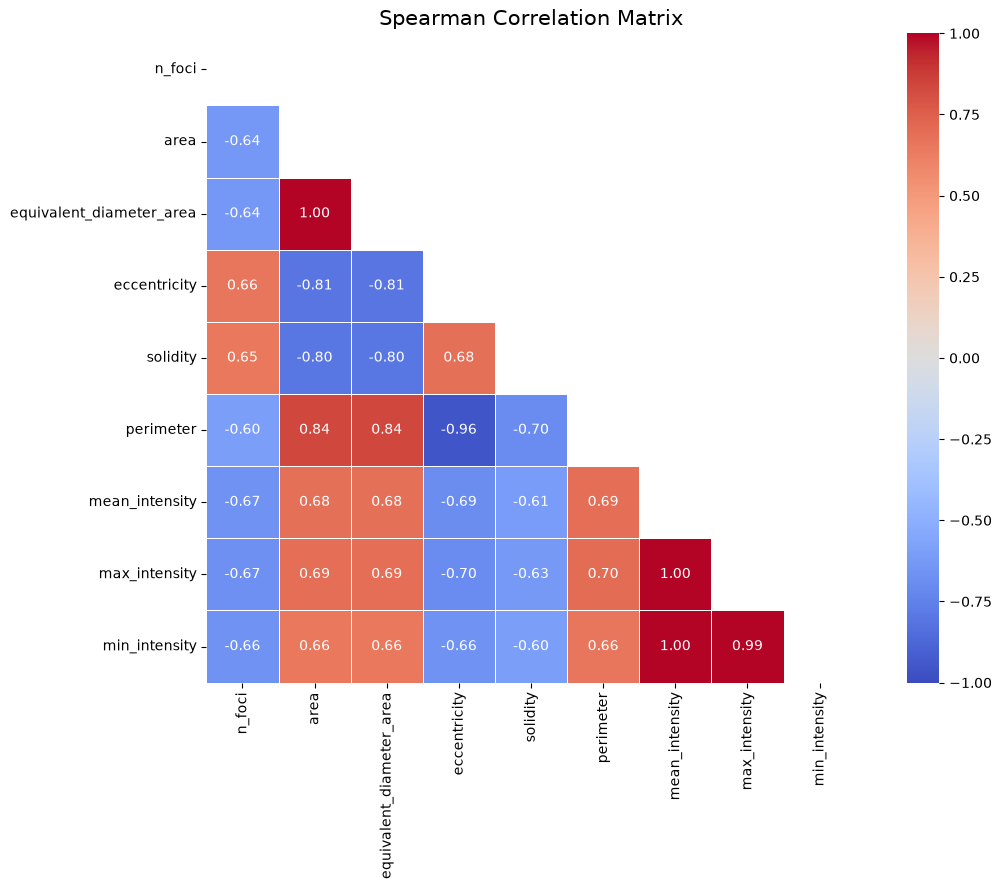

In [15]:
plt.figure(figsize=(12, 9))

# Show only lower triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Spearman Correlation Matrix", fontsize=15)
plt.tight_layout()
plt.show()

## Graphs

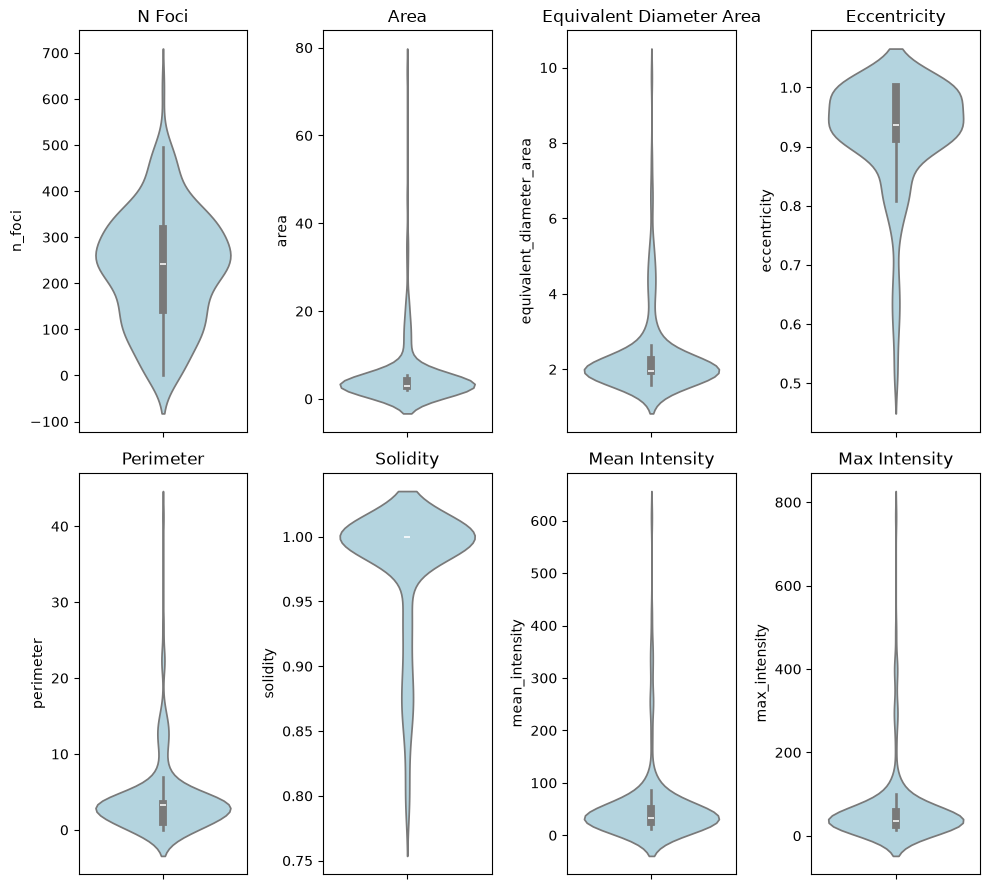

In [18]:
features = [
    "n_foci",
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
]

fig, axes = plt.subplots(2, 4, figsize=(10, 9))

for ax, feature in zip(axes.flat, features):

    sns.violinplot(
        data=df,
        y=feature,
        color="lightblue",
        inner="box",
        legend=False,
        ax=ax
    )
    
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()


# PCA

In [ ]:
# Features
features = [
    "n_foci",
    #"area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    #"max_intensity",
]

# Select features and scale them
pca_df = df.copy()

X = df[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

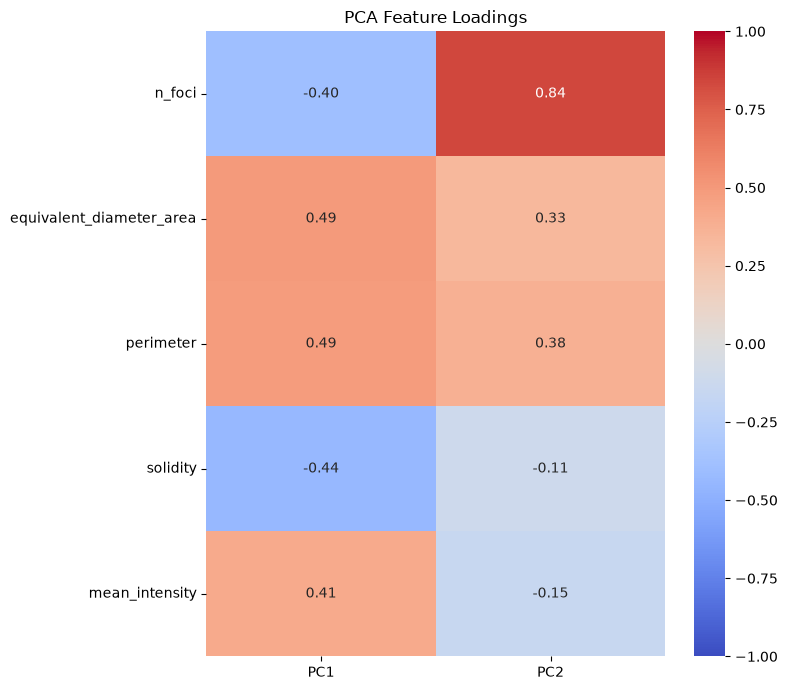

In [34]:
# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1', 'PC2']
)

#display(loadings.round(3))

# Heatmap of PCA loadings
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

In [35]:
centroids = pca_df.groupby("sample")[["PC1", "PC2"]].mean()

print(centroids)

             PC1       PC2
sample                    
MGS1   -0.064064  0.148190
MGS2   -0.169040  0.051328
MGS3    0.085067 -0.366249
MGS4    0.818776 -0.143626
MGS5   -0.175542  0.075543
WT     -0.543537  0.139498


In [ ]:
#centroids = plot_pca_centroids_ci(
    #pca_df,
    #group_col="sample",
    #confidence=0.95
#)

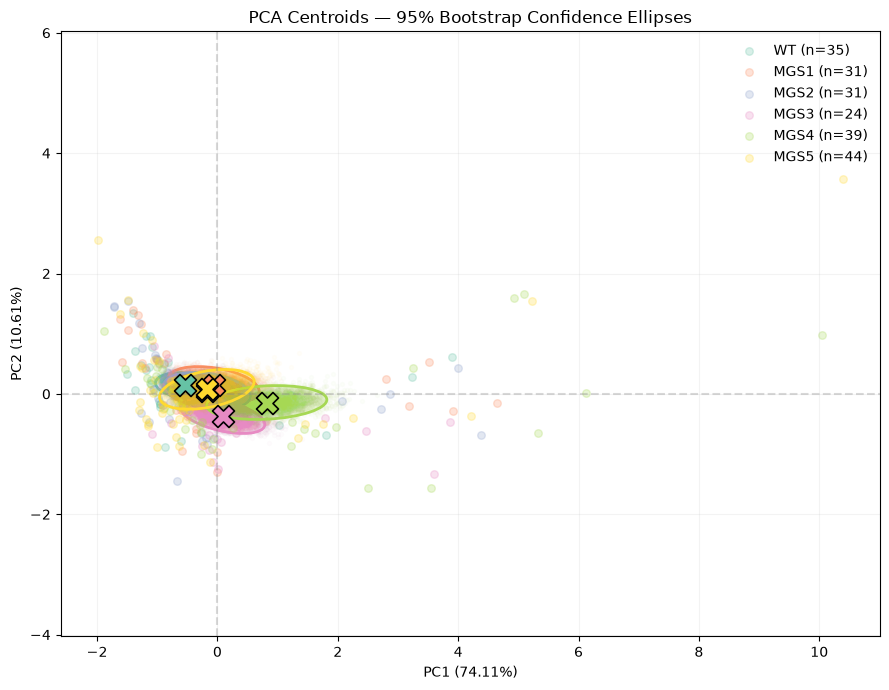

In [36]:
results_boot = bootstrap_pca_centroids(
    pca_df,
    group_col="sample",
    n_boot=5000,
    confidence=0.95,
    pca = pca
)

In [37]:
results_stats = pca_permanova(
    pca_df,
    group_col="sample"
)

results_stats

,Test,Statistic,p_value,R2,n,groups
0,PERMANOVA,2.162742,0.0398,0.051786,204,6
1,PERMDISP,1.455359,0.1972,NaN,204,6


# Detect outliers

In [ ]:
pca_df_outliers = detect_pca_outliers(
    pca_df,
    group_col="sample",
    features=("PC1", "PC2"),
    confidence=0.99
)

# Display detected outliers
outliers = pca_df_outliers[
    pca_df_outliers["outlier"]
]

display(outliers)

In [ ]:
fig, ax = plt.subplots(figsize=(9, 7))

sns.scatterplot(
    data=pca_df_outliers,
    x="PC1",
    y="PC2",
    hue="sample",
    alpha=0.5,
    s=45,
    ax=ax
)

# Highlight outliers
outliers = pca_df_outliers[pca_df_outliers["outlier"]]

ax.scatter(
    outliers["PC1"],
    outliers["PC2"],
    s=130,
    facecolors="none",
    edgecolors="red",
    linewidths=2,
    label="Outliers"
)

ax.axhline(0, color="gray", linestyle="--", alpha=0.4)
ax.axvline(0, color="gray", linestyle="--", alpha=0.4)

ax.set_title("PCA — Multivariate Outlier Detection")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
df_clean = df.loc[~df.index.isin(outliers.index)].copy()
df_clean.shape

In [ ]:
# Features
features = [
    "n_foci",
    #"area",
    "equivalent_diameter_area",
    #"eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    #"max_intensity",
]

# Select features and scale them
pca_df = df_clean.copy()

X = df_clean[features]
X_scaled = StandardScaler().fit_transform(X)

# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df["PC1"] = X_pca[:, 0]
pca_df["PC2"] = X_pca[:, 1]

In [ ]:
# PCA coefficients
loadings = pd.DataFrame(
    pca.components_.T,
    index=features,
    columns=['PC1', 'PC2']
)

#display(loadings.round(3))

# Heatmap of PCA loadings
plt.figure(figsize=(8, 7))

sns.heatmap(
    loadings[["PC1", "PC2"]],
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

In [ ]:
results_boot = bootstrap_pca_centroids(
    pca_df,
    group_col="sample",
    n_boot=5000,
    confidence=0.95,
    pca = pca
)

In [ ]:
results_stats = pca_permanova(
    pca_df,
    group_col="sample"
)

results_stats